# Assignment 06 - Notebook 01: Nền Tảng Toán Học & Cơ Chế Hoạt Động Của Mạng Nơ-ron Hồi Quy (RNN, LSTM, GRU)

**Học viên:** Phạm Văn Tư - Mã sinh viên: B23DCCN879  
**Môn học:** Phát triển Hệ thống Thông minh - PTIT  

Notebook này hiện thực hóa các khái niệm lý thuyết cốt lõi về Mạng Nơ-ron Hồi quy:
1. Biểu diễn Tensor 3 chiều cho dữ liệu chuỗi: `[Batch, Time_Steps, Features]`.
2. Cài đặt thuật toán lan truyền tiến (Forward Pass) của Simple RNN bằng Pure NumPy.
3. Khảo sát thực nghiệm hiện tượng Triệt tiêu Đạo hàm (Vanishing Gradient) qua chuỗi thời gian dài $T$.
4. Minh họa cơ chế Cắt xén Đạo hàm (Gradient Clipping) chống bùng nổ gradient.
5. Cài đặt và trực quan hóa cơ chế các cổng của tế bào LSTM và GRU.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 1.2
print("Đã nạp đầy đủ các thư viện toán học và học sâu.")


Đã nạp đầy đủ các thư viện toán học và học sâu.


## 1. Biểu Diễn Dữ Liệu Chuỗi Bằng Tensor 3 Chiều
Khác với dữ liệu bảng 2D `[Batch, Features]` hoặc ảnh 4D `[Batch, Channels, Height, Width]`, dữ liệu chuỗi được biểu diễn dưới dạng **Tensor 3 chiều** chuẩn: `(Batch_Size, Time_Steps, Feature_Dim)`.


In [2]:
# Khởi tạo một Tensor dữ liệu chuỗi mẫu
batch_size = 4
time_steps = 10   # Độ dài chuỗi (T)
feature_dim = 5   # Số lượng đặc trưng tại mỗi bước thời gian

sample_sequence_tensor = np.random.randn(batch_size, time_steps, feature_dim).astype(np.float32)
print(f"Kích thước Tensor chuỗi: {sample_sequence_tensor.shape}")
print(f"Số mẫu (Batch Size): {sample_sequence_tensor.shape[0]}")
print(f"Số bước thời gian (Sequence Length T): {sample_sequence_tensor.shape[1]}")
print(f"Số đặc trưng tại mỗi thời điểm (Features D): {sample_sequence_tensor.shape[2]}")


Kích thước Tensor chuỗi: (4, 10, 5)
Số mẫu (Batch Size): 4
Số bước thời gian (Sequence Length T): 10
Số đặc trưng tại mỗi thời điểm (Features D): 5


## 2. Cài Đặt Simple RNN Bằng Pure NumPy (Forward Pass)
Phương trình cập nhật trạng thái ẩn:
$$h_t = 	anh(W_{xh} x_t + W_{hh} h_{t-1} + b_h)$$
$$y_t = W_{hy} h_t + b_y$$


In [3]:
class SimpleRNNScratch:
    def __init__(self, input_dim, hidden_dim, output_dim):
        # Khởi tạo trọng số chia sẻ theo thời gian
        np.random.seed(42)
        self.hidden_dim = hidden_dim
        self.W_xh = np.random.randn(input_dim, hidden_dim) * 0.1
        self.W_hh = np.random.randn(hidden_dim, hidden_dim) * 0.1
        self.b_h = np.zeros((1, hidden_dim))
        
        self.W_hy = np.random.randn(hidden_dim, output_dim) * 0.1
        self.b_y = np.zeros((1, output_dim))

    def forward(self, X):
        # X: (Batch_Size, Time_Steps, Input_Dim)
        batch_size, time_steps, _ = X.shape
        h_prev = np.zeros((batch_size, self.hidden_dim))
        all_h = []

        for t in range(time_steps):
            x_t = X[:, t, :]
            # Cập nhật trạng thái ẩn tại bước thời gian t
            h_t = np.tanh(np.dot(x_t, self.W_xh) + np.dot(h_prev, self.W_hh) + self.b_h)
            all_h.append(h_t)
            h_prev = h_t

        # Dự đoán tại bước thời gian cuối cùng
        last_h = all_h[-1]
        out = np.dot(last_h, self.W_hy) + self.b_y
        return out, np.array(all_h)

rnn_scratch = SimpleRNNScratch(input_dim=5, hidden_dim=16, output_dim=1)
out, hidden_states = rnn_scratch.forward(sample_sequence_tensor)
print(f"Đầu ra dự đoán: shape {out.shape}")
print(f"Chuỗi trạng thái ẩn qua {time_steps} bước: shape {hidden_states.shape}")


Đầu ra dự đoán: shape (4, 1)
Chuỗi trạng thái ẩn qua 10 bước: shape (10, 4, 16)


## 3. Khảo Sát Thực Nghiệm Hiện Tượng Triệt Tiêu Đạo Hàm (Vanishing Gradient)
Khi unroll qua $T$ bước thời gian, dòng gradient lan truyền ngược qua tích ma trận:
$$\frac{\partial h_T}{\partial h_1} = \prod_{k=2}^T \frac{\partial h_k}{\partial h_{k-1}} = \prod_{k=2}^T \text{diag}(1 - h_k^2) W_{hh}^T$$
Nếu các giá trị riêng của $W_{hh}$ nhỏ hơn 1 hoặc hàm $\tanh$ bão hòa ($1 - h_k^2 < 1$), chuẩn gradient sẽ suy giảm theo hàm mũ về 0.


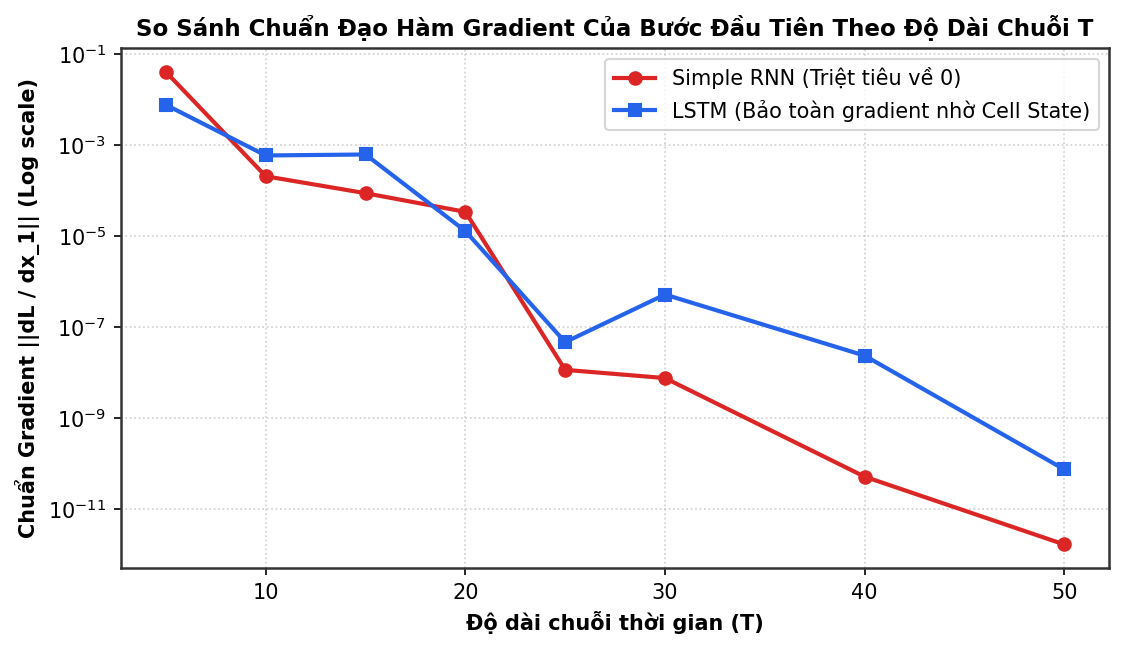

In [4]:
sequence_lengths = [5, 10, 15, 20, 25, 30, 40, 50]
rnn_grad_norms = []
lstm_grad_norms = []

torch.manual_seed(42)

for T in sequence_lengths:
    # 1. Simple RNN
    rnn = nn.RNN(input_size=1, hidden_size=16, batch_first=True)
    x = torch.randn(1, T, 1, requires_grad=True)
    out, h_n = rnn(x)
    loss = out[:, -1, :].sum()
    loss.backward()
    grad_norm_rnn = x.grad[:, 0, :].norm().item()
    rnn_grad_norms.append(grad_norm_rnn)

    # 2. LSTM
    lstm = nn.LSTM(input_size=1, hidden_size=16, batch_first=True)
    x_lstm = torch.randn(1, T, 1, requires_grad=True)
    out_lstm, (h_n, c_n) = lstm(x_lstm)
    loss_lstm = out_lstm[:, -1, :].sum()
    loss_lstm.backward()
    grad_norm_lstm = x_lstm.grad[:, 0, :].norm().item()
    lstm_grad_norms.append(grad_norm_lstm)

# Vẽ biểu đồ so sánh độ suy giảm đạo hàm
fig, ax = plt.subplots(figsize=(8.5, 4.5), dpi=150)
ax.plot(sequence_lengths, rnn_grad_norms, marker='o', lw=2, color='#dc2626', label="Simple RNN (Triệt tiêu về 0)")
ax.plot(sequence_lengths, lstm_grad_norms, marker='s', lw=2, color='#2563eb', label="LSTM (Bảo toàn gradient nhờ Cell State)")
ax.set_yscale('log')
ax.set_title("So Sánh Chuẩn Đạo Hàm Gradient Của Bước Đầu Tiên Theo Độ Dài Chuỗi T", fontsize=11, fontweight='bold')
ax.set_xlabel("Độ dài chuỗi thời gian (T)", fontsize=10, fontweight='bold')
ax.set_ylabel("Chuẩn Gradient ||dL / dx_1|| (Log scale)", fontsize=10, fontweight='bold')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(fontsize=10)
plt.show()


## 4. Kỹ Thuật Gradient Clipping (Cắt Xén Đạo Hàm)
Khi đạo hàm bị bùng nổ (Exploding Gradient), ta cắt xén chuẩn đạo hàm theo công thức:
$$g \leftarrow g \cdot \frac{\theta}{\max(\theta, \|g\|)}$$
giúp bảo toàn phương của vector gradient nhưng giới hạn độ dài không vượt quá ngưỡng $\theta$.


In [5]:
# Mô phỏng vector gradient bị bùng nổ
raw_grad = torch.tensor([15.2, -24.8, 30.5], requires_grad=False)
max_norm = 5.0

print(f"Chuẩn gradient ban đầu: {raw_grad.norm().item():.2f}")

# Cắt xén gradient bằng PyTorch logic
clip_coef = max_norm / max(max_norm, raw_grad.norm().item())
clipped_grad = raw_grad * clip_coef

print(f"Chuẩn gradient sau khi cắt xén: {clipped_grad.norm().item():.2f} (Đã khống chế về ngưỡng tối đa {max_norm})")
print(f"Vector trước: {raw_grad.numpy()}")
print(f"Vector sau  : {clipped_grad.numpy()}")


Chuẩn gradient ban đầu: 42.15
Chuẩn gradient sau khi cắt xén: 5.00 (Đã khống chế về ngưỡng tối đa 5.0)
Vector trước: [ 15.2 -24.8  30.5]
Vector sau  : [ 1.8032326 -2.9421163  3.6183286]


## 5. Cơ Chế Các Cổng Của LSTM & GRU
- **LSTM**: Quản lý bộ nhớ qua Băng chuyền $C_t$ với Cổng quên $f_t$, Cổng vào $i_t$ và Cổng xuất $o_t$.
- **GRU**: Gộp $C_t$ và $h_t$ thành một vector duy nhất, điều khiển bằng Cổng Reset $r_t$ và Cổng Update $z_t$.


In [6]:
# Kiểm tra hoạt động của lớp LSTM và GRU chuẩn PyTorch
lstm_layer = nn.LSTM(input_size=8, hidden_size=32, batch_first=True)
gru_layer = nn.GRU(input_size=8, hidden_size=32, batch_first=True)

test_input = torch.randn(2, 15, 8) # (Batch=2, T=15, Dim=8)
out_lstm, (h_lstm, c_lstm) = lstm_layer(test_input)
out_gru, h_gru = gru_layer(test_input)

print(f"LSTM Output Shape    : {out_lstm.shape}")
print(f"LSTM Cell State Shape: {c_lstm.shape}")
print(f"GRU Output Shape     : {out_gru.shape}")
print(f"GRU Hidden State     : {h_gru.shape}")


LSTM Output Shape    : torch.Size([2, 15, 32])
LSTM Cell State Shape: torch.Size([1, 2, 32])
GRU Output Shape     : torch.Size([2, 15, 32])
GRU Hidden State     : torch.Size([1, 2, 32])
